# Week 3 – Sentiment Analysis
## Review-Informed Skincare Product Discovery Using NLP and Data Analytics

**Input:** `TheDermaCo_EDA_Analysis.csv`  
**Output:** `TheDermaCo_Sentiment_Analysis.csv`

This notebook is arranged so that the dataset (`df`) is loaded and prepared before sentiment prediction. It does not install or upgrade packages.

**Environment:** Run this notebook using your `skincare-ds` Conda environment. The required libraries should already be installed.

**Language note:** The model is multilingual, but Romanized Hinglish may still be misclassified. Treat predictions as estimates and inspect examples manually.

## Step 1 – Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from transformers import pipeline, AutoTokenizer
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Libraries imported successfully!
Pandas: 3.1.0
NumPy: 2.5.4


## Step 2 – Load the EDA dataset

Keep `TheDermaCo_EDA_Analysis.csv` in the same folder as this notebook. If it is elsewhere, update `input_file` with its full path.

In [2]:
input_file = "TheDermaCo_EDA_Analysis.csv"

df = pd.read_csv(input_file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
display(df.head())

Dataset loaded successfully!
Dataset shape: (162, 17)
Available columns: ['review_id', 'product_name', 'reviewer_name', 'rating', 'review_title', 'review_text', 'review_date', 'verified_buyer', 'helpful_votes', 'not_helpful_votes', 'product_url', 'combined_review', 'cleaned_review', 'is_product_name_only', 'review_length', 'character_count', 'review_date_parsed']


,review_id,product_name,reviewer_name,rating,review_title,review_text,review_date,verified_buyer,helpful_votes,not_helpful_votes,product_url,combined_review,cleaned_review,is_product_name_only,review_length,character_count,review_date_parsed
0,e18ed183-d1fb-4f47-9e5c-84e2edb3010b,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Tejas,5,Good,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2026-09-13T05:10:00Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,Good 2% Sali-Cinamide Anti-Acne Face Wash with...,good 2 sali cinamide anti acne face wash with...,True,18,100,2026-09-13 05:10:00+00:00
1,8d555059-7343-4220-a9aa-98144cd5156e,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Kabibunisa,5,NaN,It is the super product for pimple remove,2026-08-14T02:29:15Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,It is the super product for pimple remove,it is the super product for pimple remove,False,8,41,2026-08-14 02:29:15+00:00
2,a4d3af1b-81db-4efd-8667-1dc49e7deb3d,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Sayma,5,Fight acne and oil control,"Yeh derma ka best facewash h isme niacinamide,...",2026-08-07T05:40:16Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,Fight acne and oil control Yeh derma ka best f...,fight acne and oil control yeh derma ka best f...,False,80,418,2026-08-07 05:40:16+00:00
3,1c619545-cd14-477e-9c28-5abe6fc21b9b,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Athar .,5,NaN,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2026-08-02T07:12:10Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,2 sali cinamide anti acne face wash with 2 s...,True,17,95,2026-08-02 07:12:10+00:00
4,58d6f486-ec74-469e-b82b-ad8c4190fdfc,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Lucky,5,NaN,Nice,2026-02-22T05:52:29Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-...,Nice,nice,False,1,4,2026-02-22 05:52:29+00:00


## Step 3 – Validate columns and prepare review text

In [3]:
required_columns = ["rating", "review_title", "review_text"]
missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns missing from CSV: {missing_columns}")

df["review_title"] = df["review_title"].fillna("").astype(str)
df["review_text"] = df["review_text"].fillna("").astype(str)

df["combined_review"] = (
    df["review_title"] + " " + df["review_text"]
).str.strip()

# Keep only rows containing review text.
df = df[df["combined_review"].str.len() > 0].copy()
df.reset_index(drop=True, inplace=True)

print("Reviews available for sentiment analysis:", len(df))
display(df[["rating", "combined_review"]].head())

Reviews available for sentiment analysis: 162


,rating,combined_review
0,5,Good 2% Sali-Cinamide Anti-Acne Face Wash with...
1,5,It is the super product for pimple remove
2,5,Fight acne and oil control Yeh derma ka best f...
3,5,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...
4,5,Nice


## Step 4 – Load the multilingual sentiment model

The model is downloaded from Hugging Face on the first run. An internet connection is required. `use_fast=False` selects the SentencePiece-based tokenizer and avoids the TikToken fallback encountered earlier.

In [4]:
MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False
)

sentiment_model = pipeline(
    task="sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=tokenizer,
    device=-1  # CPU; change to 0 only if a compatible CUDA GPU is configured.
)

print("Sentiment model loaded successfully!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Sentiment model loaded successfully!


## Step 5 – Predict sentiment

This cell uses the already-created `df` and `combined_review` column. It processes reviews in batches.

In [5]:
reviews = df["combined_review"].tolist()

raw_results = sentiment_model(
    reviews,
    batch_size=16,
    truncation=True,
    max_length=512
)

print("Sentiment predictions completed:", len(raw_results))

Sentiment predictions completed: 162


## Step 6 – Convert model labels into readable sentiment classes

The model configuration supplies the label mapping. The helper handles both labels such as `LABEL_0` and labels already named `negative`, `neutral`, or `positive`.

In [6]:
id2label = sentiment_model.model.config.id2label
print("Model label mapping:", id2label)

def normalize_sentiment(result):
    raw_label = str(result["label"]).strip()
    normalized = raw_label.lower()

    if normalized.startswith("label_"):
        label_id = int(normalized.split("_")[-1])
        mapped_label = id2label.get(
            label_id,
            id2label.get(str(label_id), raw_label)
        )
        normalized = str(mapped_label).lower()

    if "neg" in normalized:
        return "Negative"
    elif "neu" in normalized:
        return "Neutral"
    elif "pos" in normalized:
        return "Positive"
    else:
        raise ValueError(f"Could not map model label: {raw_label}")

df["sentiment"] = [normalize_sentiment(result) for result in raw_results]
df["sentiment_confidence"] = [
    float(result["score"]) for result in raw_results
]

display(
    df[["rating", "combined_review", "sentiment", "sentiment_confidence"]].head(10)
)

Model label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}


,rating,combined_review,sentiment,sentiment_confidence
0,5,Good 2% Sali-Cinamide Anti-Acne Face Wash with...,Neutral,0.782745
1,5,It is the super product for pimple remove,Positive,0.545851
2,5,Fight acne and oil control Yeh derma ka best f...,Positive,0.478471
3,5,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Neutral,0.830566
4,5,Nice,Positive,0.473958
5,5,2% Sali-Cinamide Anti-Acne Face Wash with 2% S...,Neutral,0.816672
6,5,This product is super awesome. I started using...,Positive,0.771283
7,5,Absolutely w... Absolutely worth it product\nI...,Negative,0.539113
8,5,This anti ac... This anti acne face wash is go...,Positive,0.615807
9,5,This product... This product is great for sens...,Positive,0.707355


## Step 7 – Inspect individual predictions

In [7]:
for index in range(min(10, len(df))):
    print("Review:", df.loc[index, "combined_review"])
    print("Predicted sentiment:", df.loc[index, "sentiment"])
    print("Confidence:", round(df.loc[index, "sentiment_confidence"], 4))
    print("-" * 70)

Review: Good 2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2)
Predicted sentiment: Neutral
Confidence: 0.7827
----------------------------------------------------------------------
Review: It is the super product for pimple remove
Predicted sentiment: Positive
Confidence: 0.5459
----------------------------------------------------------------------
Review: Fight acne and oil control Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liye better h
Muje derma ke sabhi products bhot hi pasand aye
Inki suncream, moisturizer, facewash sabhi best h
Yeh facewash acne wali skin ki key hii smjh lo
This facewash is too good 💞💞
Jinko bhi pimple h toh wo derma ka yeh facewash le sakta h bhot ache products h derma ke
Thank you so much derma team ❤✨
Predicted sentiment: Positive
Confidence: 0.4785
----------------------------------------------------------------------
Review: 2% Sali-Cinamide Anti-Acne Face Wash with 2

## Step 8 – Calculate sentiment counts and percentages

In [8]:
sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

sentiment_summary = pd.DataFrame({
    "Review_Count": sentiment_counts,
    "Percentage": (sentiment_counts / len(df) * 100).round(2)
})

display(sentiment_summary)

,Review_Count,Percentage
sentiment,,
Positive,137,84.57
Neutral,15,9.26
Negative,10,6.17


## Step 9 – Visualize sentiment distribution

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("TheDermaCo_EDA_Analysis.csv")

print("Dataset loaded:", df.shape)

Dataset loaded: (162, 17)


In [7]:
df["review_title"] = df["review_title"].fillna("").astype(str)
df["review_text"] = df["review_text"].fillna("").astype(str)

df["combined_review"] = (
    df["review_title"] + " " + df["review_text"]
).str.strip()

df = df[df["combined_review"].str.len() > 0].copy()
df = df.reset_index(drop=True)

In [8]:
from transformers import pipeline, AutoTokenizer

MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False
)

sentiment_model = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=tokenizer,
    device=-1
)

print("Model loaded!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded!


In [9]:
reviews = df["combined_review"].tolist()

raw_results = sentiment_model(
    reviews,
    batch_size=16,
    truncation=True,
    max_length=512
)

id2label = sentiment_model.model.config.id2label

def normalize_sentiment(result):
    label = result["label"].lower()

    if label.startswith("label_"):
        label_id = int(label.split("_")[1])
        label = str(id2label[label_id]).lower()

    if "neg" in label:
        return "Negative"
    elif "neu" in label:
        return "Neutral"
    elif "pos" in label:
        return "Positive"

    raise ValueError(f"Unknown label: {label}")

df["sentiment"] = [
    normalize_sentiment(result) for result in raw_results
]

df["sentiment_confidence"] = [
    result["score"] for result in raw_results
]

print(df["sentiment"].value_counts())

sentiment
Positive    137
Neutral      15
Negative     10
Name: count, dtype: int64


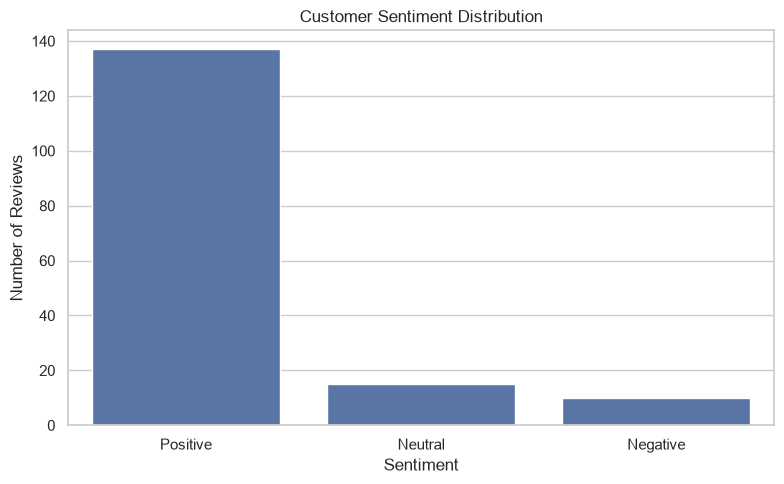

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [14]:
sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

sentiment_summary = pd.DataFrame({
    "Review_Count": sentiment_counts,
    "Percentage": (
        sentiment_counts / len(df) * 100
    ).round(2)
})

display(sentiment_summary)

,Review_Count,Percentage
sentiment,,
Positive,137,84.57
Neutral,15,9.26
Negative,10,6.17


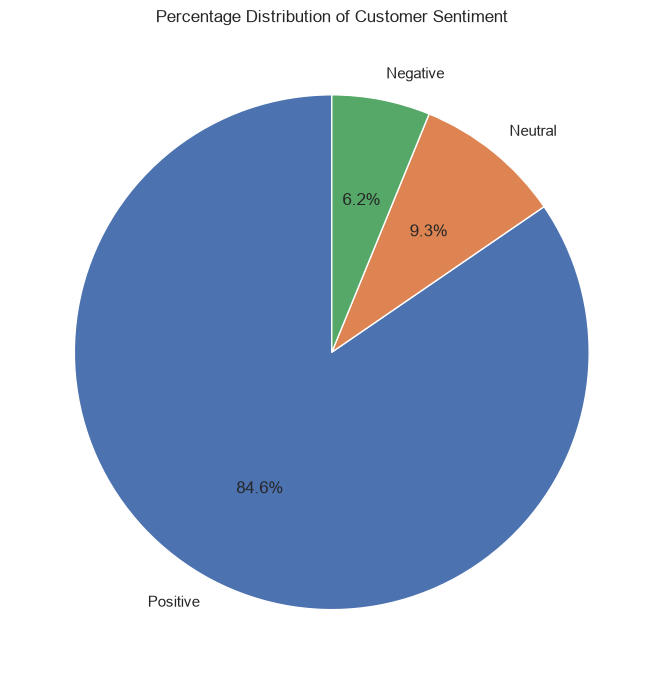

In [15]:
nonzero_summary = sentiment_summary[
    sentiment_summary["Review_Count"] > 0
]

plt.figure(figsize=(7, 7))

plt.pie(
    nonzero_summary["Review_Count"],
    labels=nonzero_summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Customer Sentiment")
plt.tight_layout()
plt.show()

## Step 10 – Compare predicted sentiment with star ratings

This comparison is exploratory. Star ratings are not verified sentiment labels and should not be treated as ground truth for measuring model accuracy.

In [17]:
sentiment_rating = pd.crosstab(
    df["rating"],
    df["sentiment"]
).reindex(columns=sentiment_order, fill_value=0)

display(sentiment_rating)

sentiment,Positive,Neutral,Negative
rating,,,
1,0,2,2
4,23,3,0
5,114,10,8


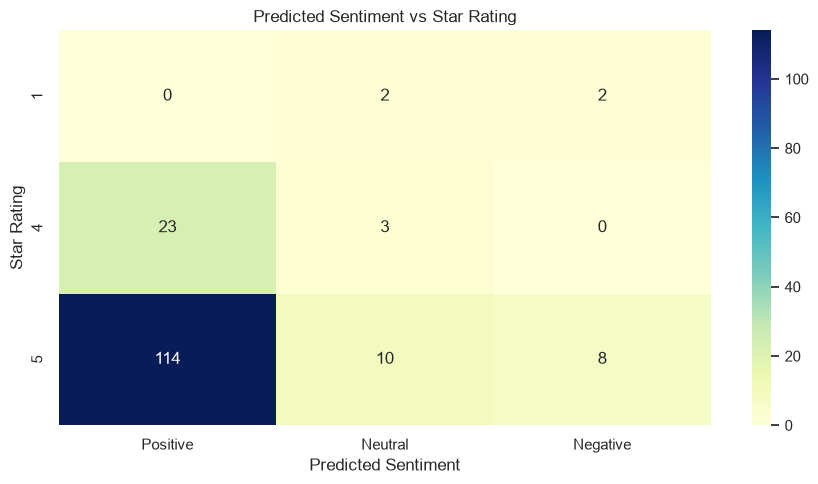

In [18]:
plt.figure(figsize=(9, 5))
sns.heatmap(
    sentiment_rating,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)
plt.title("Predicted Sentiment vs Star Rating")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Star Rating")
plt.tight_layout()
plt.show()

## Step 11 – Inspect positive and negative review examples

In [19]:
positive_reviews = df[
    df["sentiment"] == "Positive"
].sort_values(
    "sentiment_confidence",
    ascending=False
)

display(
    positive_reviews[
        ["rating", "combined_review", "sentiment_confidence"]
    ].head(10)
)

,rating,combined_review,sentiment_confidence
44,5,Loved it ... Loved it,0.908910
38,5,This is bril... This is brilliant and my favou...,0.903724
155,4,It's really ... It's really good,0.884138
132,4,I really like this Face Wash. It cleans my ski...,0.879822
114,5,This is the ... This is the best facewash I ha...,0.877718
103,5,Great for o... Great for oil control; my face ...,0.870501
34,5,Loving how Loving how clean and smooth my skin...,0.848799
104,5,Amazing pro... Amazing product! Really helped ...,0.848245
144,4,Super impre Super impressed by how well Salicy...,0.843922
100,5,It's really ... It's really awesome guys. I ne...,0.841222


In [20]:
negative_reviews = df[
    df["sentiment"] == "Negative"
].sort_values(
    "sentiment_confidence",
    ascending=False
)

display(
    negative_reviews[
        ["rating", "combined_review", "sentiment_confidence"]
    ].head(10)
)

,rating,combined_review,sentiment_confidence
158,1,Missing product I ordered 4 item but got only ...,0.933387
123,5,I was worrie... I was worried about my acne an...,0.923665
127,5,Oily and acne-p... Oily and acne-prone skin is...,0.905185
125,5,Face wash is su... Face wash is surely the mos...,0.867595
76,5,My all acnes... My all acnes gone after using ...,0.628692
7,5,Absolutely w... Absolutely worth it product\nI...,0.539113
59,5,"I have tried... I have tried many face washes,...",0.538114
88,5,I am using i... I am using it more than 5 mont...,0.466822
160,1,ek no. ka farji app h mere sath frod huaa suns...,0.385972
120,5,It fades my ... It fades my acne marks and goo...,0.359473


## Step 12 – Inspect low-confidence predictions

Low confidence can help prioritize manual review. A high confidence score does not guarantee that a prediction is correct.

In [21]:
low_confidence_reviews = df[
    df["sentiment_confidence"] < 0.60
].sort_values("sentiment_confidence")

print("Low-confidence reviews:", len(low_confidence_reviews))

display(
    low_confidence_reviews[
        ["rating", "combined_review", "sentiment", "sentiment_confidence"]
    ].head(20)
)

Low-confidence reviews: 58


,rating,combined_review,sentiment,sentiment_confidence
120,5,It fades my ... It fades my acne marks and goo...,Negative,0.359473
151,4,I have strug... I have struggled with acne-pro...,Positive,0.360714
160,1,ek no. ka farji app h mere sath frod huaa suns...,Negative,0.385972
152,4,Reduces pim... Reduces pimples and controls oi...,Neutral,0.387254
60,5,The salicina The salicinamide face wash helped...,Neutral,0.422374
135,4,I am using d... I am using derma co 2% sali-ci...,Positive,0.430625
50,5,This salicyli This salicylic acid and niacinam...,Positive,0.431922
89,5,I am a oily ... I am a oily skin person and al...,Positive,0.441888
122,5,This face wa... This face wash helps remove ex...,Positive,0.448049
86,5,Worked for m... Worked for me,Neutral,0.453859


## Step 13 – Export the sentiment dataset

In [22]:
output_file = "TheDermaCo_Sentiment_Analysis.csv"

df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Sentiment dataset exported successfully!")
print("Output file:", output_file)
print("Total analyzed reviews:", len(df))

Sentiment dataset exported successfully!
Output file: TheDermaCo_Sentiment_Analysis.csv
Total analyzed reviews: 162


## Step 14 – Final summary

In [23]:
print("=" * 55)
print("THE DERMA CO – SENTIMENT ANALYSIS SUMMARY")
print("=" * 55)
print("Total reviews analyzed:", len(df))

for sentiment in sentiment_order:
    count = int((df["sentiment"] == sentiment).sum())
    percentage = count / len(df) * 100 if len(df) else 0
    print(f"{sentiment}: {count} reviews ({percentage:.2f}%)")

print("-" * 55)
print("Average model confidence:", round(df["sentiment_confidence"].mean(), 4))
print("Exported file:", output_file)
print("=" * 55)

THE DERMA CO – SENTIMENT ANALYSIS SUMMARY
Total reviews analyzed: 162
Positive: 137 reviews (84.57%)
Neutral: 15 reviews (9.26%)
Negative: 10 reviews (6.17%)
-------------------------------------------------------
Average model confidence: 0.6556
Exported file: TheDermaCo_Sentiment_Analysis.csv


## Interpretation and limitations

- Report the predicted sentiment counts and percentages.
- Read examples from all three sentiment classes before drawing conclusions.
- Manually inspect Romanized Hinglish reviews; the model may not reliably understand code-mixed text.
- A confidence score is not an accuracy score.
- Do not claim model accuracy unless you create a manually labelled validation set and evaluate predictions against it.
- If the kernel is restarted, run the notebook from Step 1 in order. This recreates `df`, `sentiment_model`, `reviews`, and the prediction results.